# Handling Outliers

## Learning objectives
- Identify potential outliers with the interquartile range (IQR).
- Visualize a numeric distribution.
- Compare filtering and capping.

An outlier is unusual, but it is not automatically an error. Domain knowledge is important.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({"TransactionAmount": [12, 15, 14, 18, 21, 17, 16, 19, 20, 22, 18, 250]})
df.describe()

,TransactionAmount
count,12.000000
mean,36.833333
std,67.192848
min,12.000000
25%,15.750000
50%,18.000000
75%,20.250000
max,250.000000


## 1. Visualize the distribution

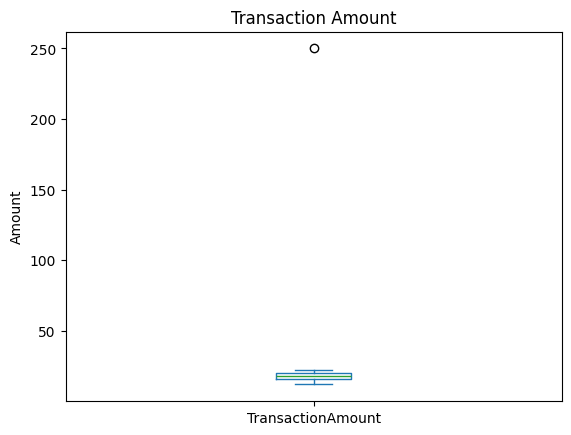

In [2]:
df["TransactionAmount"].plot(kind="box", title="Transaction Amount")
plt.ylabel("Amount")
plt.show()

## 2. Detect potential outliers with IQR
The common rule flags values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR.

In [3]:
column = df["TransactionAmount"]
q1 = column.quantile(0.25)
q3 = column.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outlier_mask = (column < lower_bound) | (column > upper_bound)
print("Q1:", q1, "Q3:", q3, "IQR:", iqr)
print("Bounds:", lower_bound, upper_bound)
df.loc[outlier_mask]

Q1: 15.75 Q3: 20.25 IQR: 4.5
Bounds: 9.0 27.0


,TransactionAmount
11,250


## 3. Filter potential outliers
Filtering removes rows outside the selected bounds. It may also remove valid rare events, so do not apply it automatically.

In [4]:
filtered_df = df.loc[~outlier_mask].copy()
print("Original rows:", len(df))
print("Rows after filtering:", len(filtered_df))
filtered_df

Original rows: 12
Rows after filtering: 11


,TransactionAmount
0,12
1,15
2,14
3,18
4,21
5,17
6,16
7,19
8,20
9,22


## 4. Cap extreme values
Capping preserves the number of rows but replaces values beyond the bounds.

In [5]:
capped_df = df.copy()
capped_df["TransactionAmount"] = capped_df["TransactionAmount"].clip(lower_bound, upper_bound)
pd.DataFrame({"Original": df["TransactionAmount"], "Capped": capped_df["TransactionAmount"]})

,Original,Capped
0,12,12
1,15,15
2,14,14
3,18,18
4,21,21
5,17,17
6,16,16
7,19,19
8,20,20
9,22,22


## Key takeaways
- IQR rules flag potential outliers; they do not prove a value is wrong.
- Use plots and domain knowledge before modifying data.
- Filtering reduces sample size; capping changes extreme values.
- For predictive evaluation, learn thresholds from training data only.